# COPA-DATA filler M7: anomaly findings

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/leon-adsk/copa/blob/jbt/notebooks/anomaly_findings_colab.ipynb)

**How to use:** press ▶ on each cell from top to bottom (or *Run All*). It works in three ways:

| where | kernel | data |
|---|---|---|
| VS Code | local Python (e.g. the project's uv environment) | your local repo (`data/txt`) |
| VS Code + Colab extension | Colab server | cloned from GitHub (branch `jbt`, needs a token) |
| Browser, colab.research.google.com | Colab server | cloned from GitHub (branch `jbt`, needs a token) |

**Data:** the raw zenon exports from COPA-DATA in `data/txt` (Git LFS). Nothing is simulated.
All analysis code lives in `analysis/` (`copa_data.py` loading, `detectors.py` methods, `run_analysis.py` pipeline).

In [1]:
# @title 1 · Setup: find the repo locally, or clone it on a Colab server
BRANCH = "jbt"                          # branch with the analysis/ folder (push it first)
REPO_URL = "github.com/leon-adsk/copa.git"

import os, sys, shutil, subprocess, getpass
from pathlib import Path

def find_local_repo():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "analysis" / "copa_data.py").exists() and (p / "data" / "txt").exists():
            return p
    return None

REPO = find_local_repo()
WHERE = "local repo"
if REPO is None:                         # remote runtime (Colab): clone the private repo
    WHERE = f"cloned from GitHub (branch {BRANCH})"
    REPO = Path("/content/copa")
    if not (REPO / "analysis").exists():
        try:                             # Colab secret "GITHUB_TOKEN" (key icon in the browser UI) ...
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:                # ... otherwise type it in (not stored in the notebook)
            token = getpass.getpass("GitHub token with read access to leon-adsk/copa: ")
        if shutil.which("git-lfs") is None:
            subprocess.run("apt-get -qq install -y git-lfs", shell=True, check=True)
        r = subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, f"https://{token}@{REPO_URL}", str(REPO)],
                           env={**os.environ, "GIT_LFS_SKIP_SMUDGE": "1"}, capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError(f"git clone failed: check the token and that branch '{BRANCH}' is pushed")
        subprocess.run(["git", "lfs", "install", "--local"], cwd=REPO, check=True, capture_output=True)
        subprocess.run(["git", "lfs", "pull", "--include", "data/txt/*"], cwd=REPO, check=True, capture_output=True)
        subprocess.run(["git", "remote", "set-url", "origin", f"https://{REPO_URL}"], cwd=REPO, check=True)
        del token

os.chdir(REPO)
sys.path.insert(0, str(REPO / "analysis"))
print("using:", WHERE)
print("raw exports:", sorted(p.name for p in (REPO / "data" / "txt").glob("*.TXT")))

using: local repo
raw exports: ['07261104141229_07.TXT', '07261120103434_07.TXT', '17261104141251_17.TXT', '17261120103538_17.TXT', 'FP261104141238_FP.TXT', 'FP261120103526_FP.TXT']


In [2]:
# @title 2 · Run the pipeline (about 30 s): raw TXT -> tables, figures, metrics in results/
import subprocess, sys
r = subprocess.run([sys.executable, "analysis/run_analysis.py", "--out", "results", "--skip-processed"],
                   capture_output=True, text=True)
print(r.stdout[-1500:])
if r.returncode != 0:
    print(r.stderr[-3000:])
    raise RuntimeError("pipeline failed (see error above)")

[   0.0s] loading raw exports
[   5.7s] rolling features
[   6.0s] characterisation
[   6.2s] D1 frequency ranking
[   7.5s] D2 envelope episodes
[   8.6s] RQ1 detector comparison
[  10.7s] RQ2 online vs batch
[  11.0s] RQ3 sampling interval experiment
[  16.0s] RQ3 deadband experiment
[  21.0s] RQ3 export comparison
[  21.4s] slide figures
[  21.8s] done



In [3]:
# @title 3 · Helpers to show the results
import json
import pandas as pd
from IPython.display import Image, Markdown, display

RES = REPO / "results"; FIG = RES / "figures"; TAB = RES / "tables"
M = json.loads((RES / "metrics.json").read_text())
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 220)

def show(name, width=1100):
    display(Image(filename=str(FIG / name), width=width))

## 1 · The data
Two exports of the same three zenon archives. They do **not** overlap: Export 2 starts where Export 1 ends.
Only Export 1 has a label from COPA-DATA (Andreas Grün, mail 13.11.2026): anomalies until 04.11. ~10:50, none from 10:50 to 15:00.

,export,archive,file,rows,invalid_rows,first,last,recording,median_interval_s
0,old_3s,FP,FP261104141238_FP.TXT,2007441,0,29.10.2026 06:50:00,04.11.2026 15:00:00,cyclic 3 s,3.0000
1,old_3s,17,17261104141251_17.TXT,730242,0,29.10.2026 06:50:00,04.11.2026 15:00:00,cyclic 3 s,3.0000
2,old_3s,07,07261104141229_07.TXT,4673,0,29.10.2026 06:53:09,04.11.2026 15:00:00,on change,24.9485
3,new_10s,FP,FP261120103526_FP.TXT,1504811,2992,04.11.2026 15:00:00,20.11.2026 11:00:00,cyclic 10 s,10.0000
4,new_10s,17,17261120103538_17.TXT,547204,1088,04.11.2026 15:00:00,20.11.2026 11:00:00,cyclic 10 s,10.0000
5,new_10s,07,07261120103434_07.TXT,11865,6,04.11.2026 15:00:00,20.11.2026 11:00:00,on change,21.2000


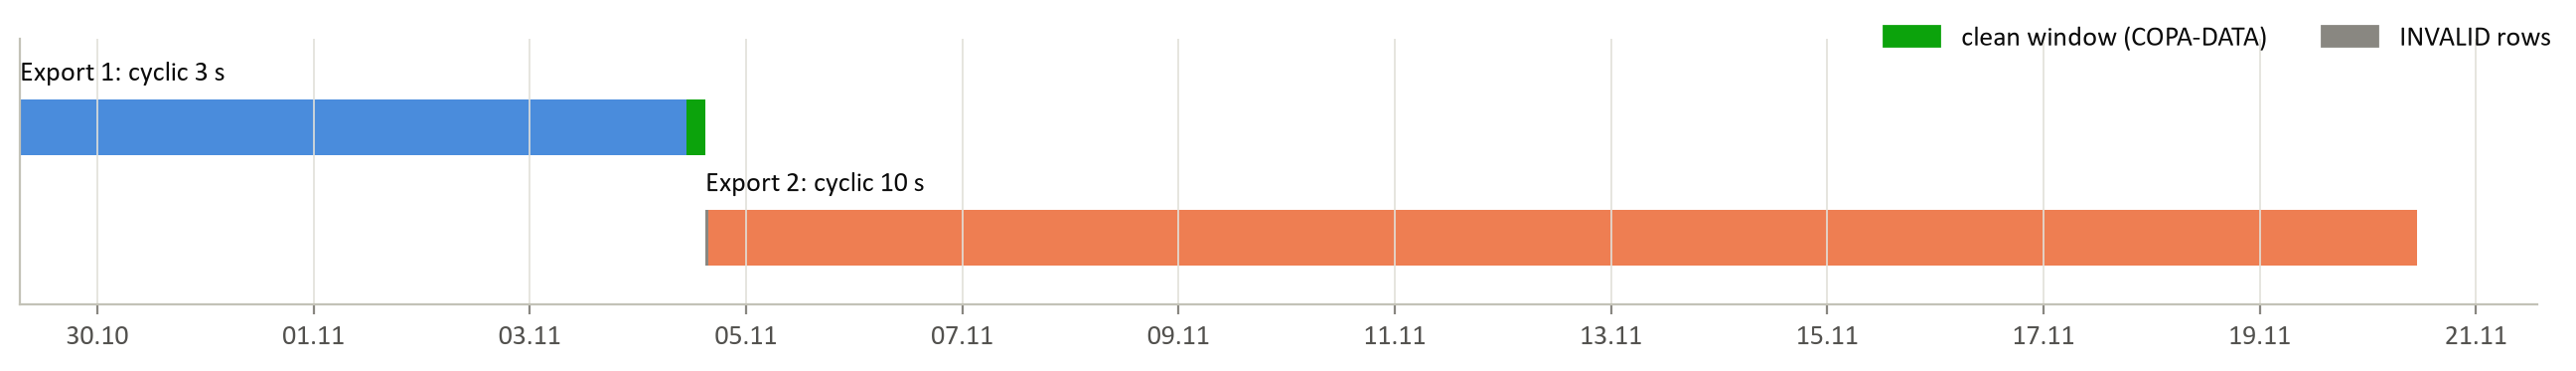

In [4]:
inv = pd.read_csv(TAB / "data_inventory.csv")
display(inv[["export", "archive", "file", "rows", "invalid_rows", "first", "last", "recording", "median_interval_s"]])
show("fig01_export_timeline.png")

## 2 · Idea: rank the values by how often they occur (the "descending list")
Assumption: most rows are normal, so very rare values are anomaly candidates.
The ranking is done **per operating state** (running / stopped), otherwise every stop would look rare.
A value counts as *rare* if it occurs in fewer than 1 of 10,000 rows of its state.

**Fill weight while running, Export 1: 320 distinct values. Most frequent (normal):**

,value,rows,share_pct,cum_share_pct,rank,rare
0,500.5,3305,2.680128,2.680128,1,False
1,500.1,3290,2.667964,5.348092,2,False
2,499.6,3234,2.622552,7.970644,3,False
3,500.4,3205,2.599035,10.569679,4,False
4,500.3,3160,2.562543,13.132222,5,False
5,499.8,3151,2.555245,15.687467,6,False
6,500.2,3141,2.547135,18.234602,7,False
7,500.7,3098,2.512265,20.746868,8,False
8,499.9,3098,2.512265,23.259133,9,False
9,500.0,3020,2.449013,25.708146,10,False


**Rarest values (anomaly candidates):**

,value,rows,share_pct,cum_share_pct,rank,rare
310,488.7,1,0.000811,99.992702,311,True
311,488.4,1,0.000811,99.993513,312,True
312,491.0,1,0.000811,99.994323,313,True
313,515.0,1,0.000811,99.995134,314,True
314,506.6,1,0.000811,99.995945,315,True
315,490.6,1,0.000811,99.996756,316,True
316,490.8,1,0.000811,99.997567,317,True
317,516.9,1,0.000811,99.998378,318,True
318,516.0,1,0.000811,99.999189,319,True
319,487.7,1,0.000811,100.000000,320,True


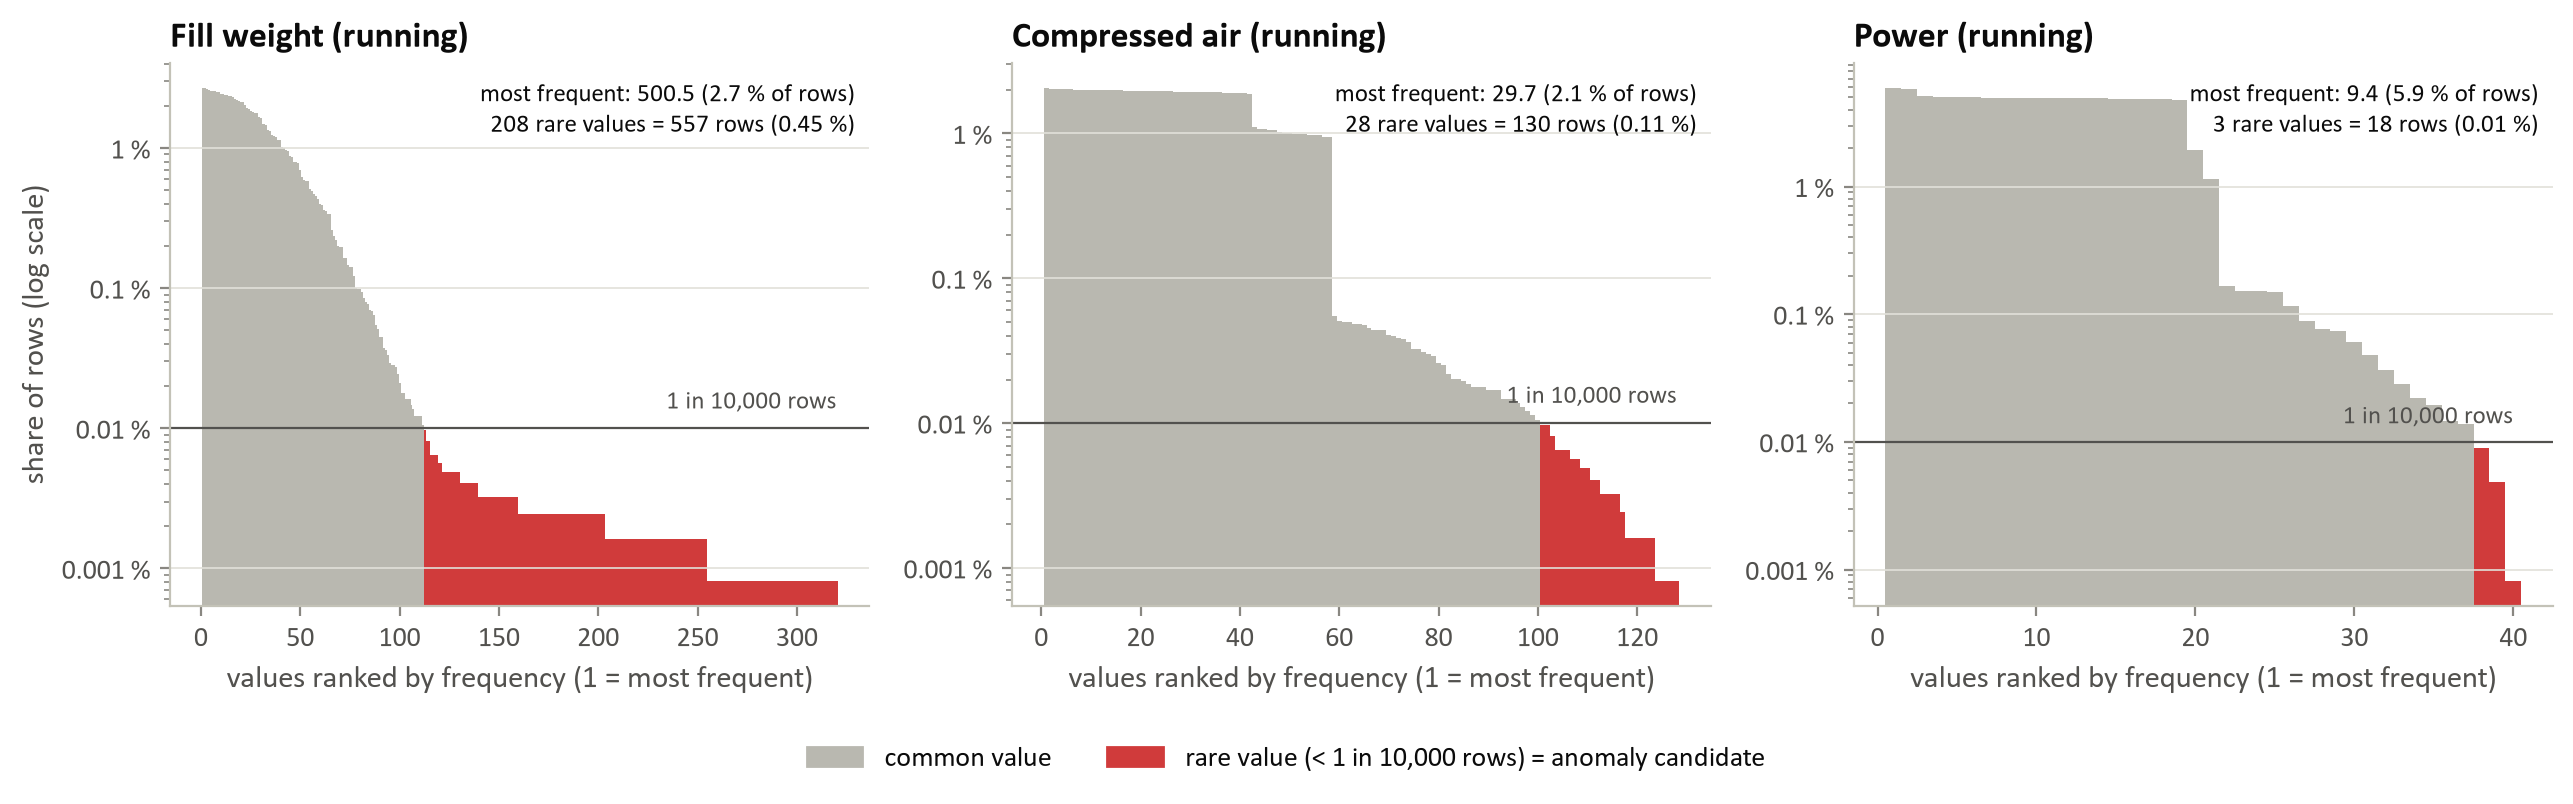

In [5]:
t = pd.read_csv(TAB / "frequency_ranking" / "old_3s__running__fill_weight.csv")
display(Markdown(f"**Fill weight while running, Export 1: {len(t)} distinct values. Most frequent (normal):**"))
display(t.head(10))
display(Markdown("**Rarest values (anomaly candidates):**"))
display(t.tail(10))
show("fig02_frequency_ranking.png")

In [6]:
# The code behind it (analysis/detectors.py)
import inspect, detectors as D
print(inspect.getsource(D.frequency_table))
print(inspect.getsource(D.frequency_flags))

def frequency_table(values: pd.Series, tau: float = 1e-4) -> pd.DataFrame:
    """The 'descending list': every observed value with its share of rows, most frequent first."""
    vc = values.dropna().round(1).value_counts()
    t = pd.DataFrame({"value": vc.index.to_numpy(), "rows": vc.to_numpy()})
    t["share_pct"] = 100 * t["rows"] / t["rows"].sum()
    t["cum_share_pct"] = t["share_pct"].cumsum()
    t["rank"] = np.arange(1, len(t) + 1)
    t["rare"] = t["share_pct"] < 100 * tau
    return t

def frequency_flags(shares: pd.DataFrame, tau: float = 1e-4) -> pd.DataFrame:
    return shares.lt(tau) & shares.notna()



## 3 · Where the rare values lie
If the idea works, rare values appear in the anomaly period and **not** in the clean window (green).

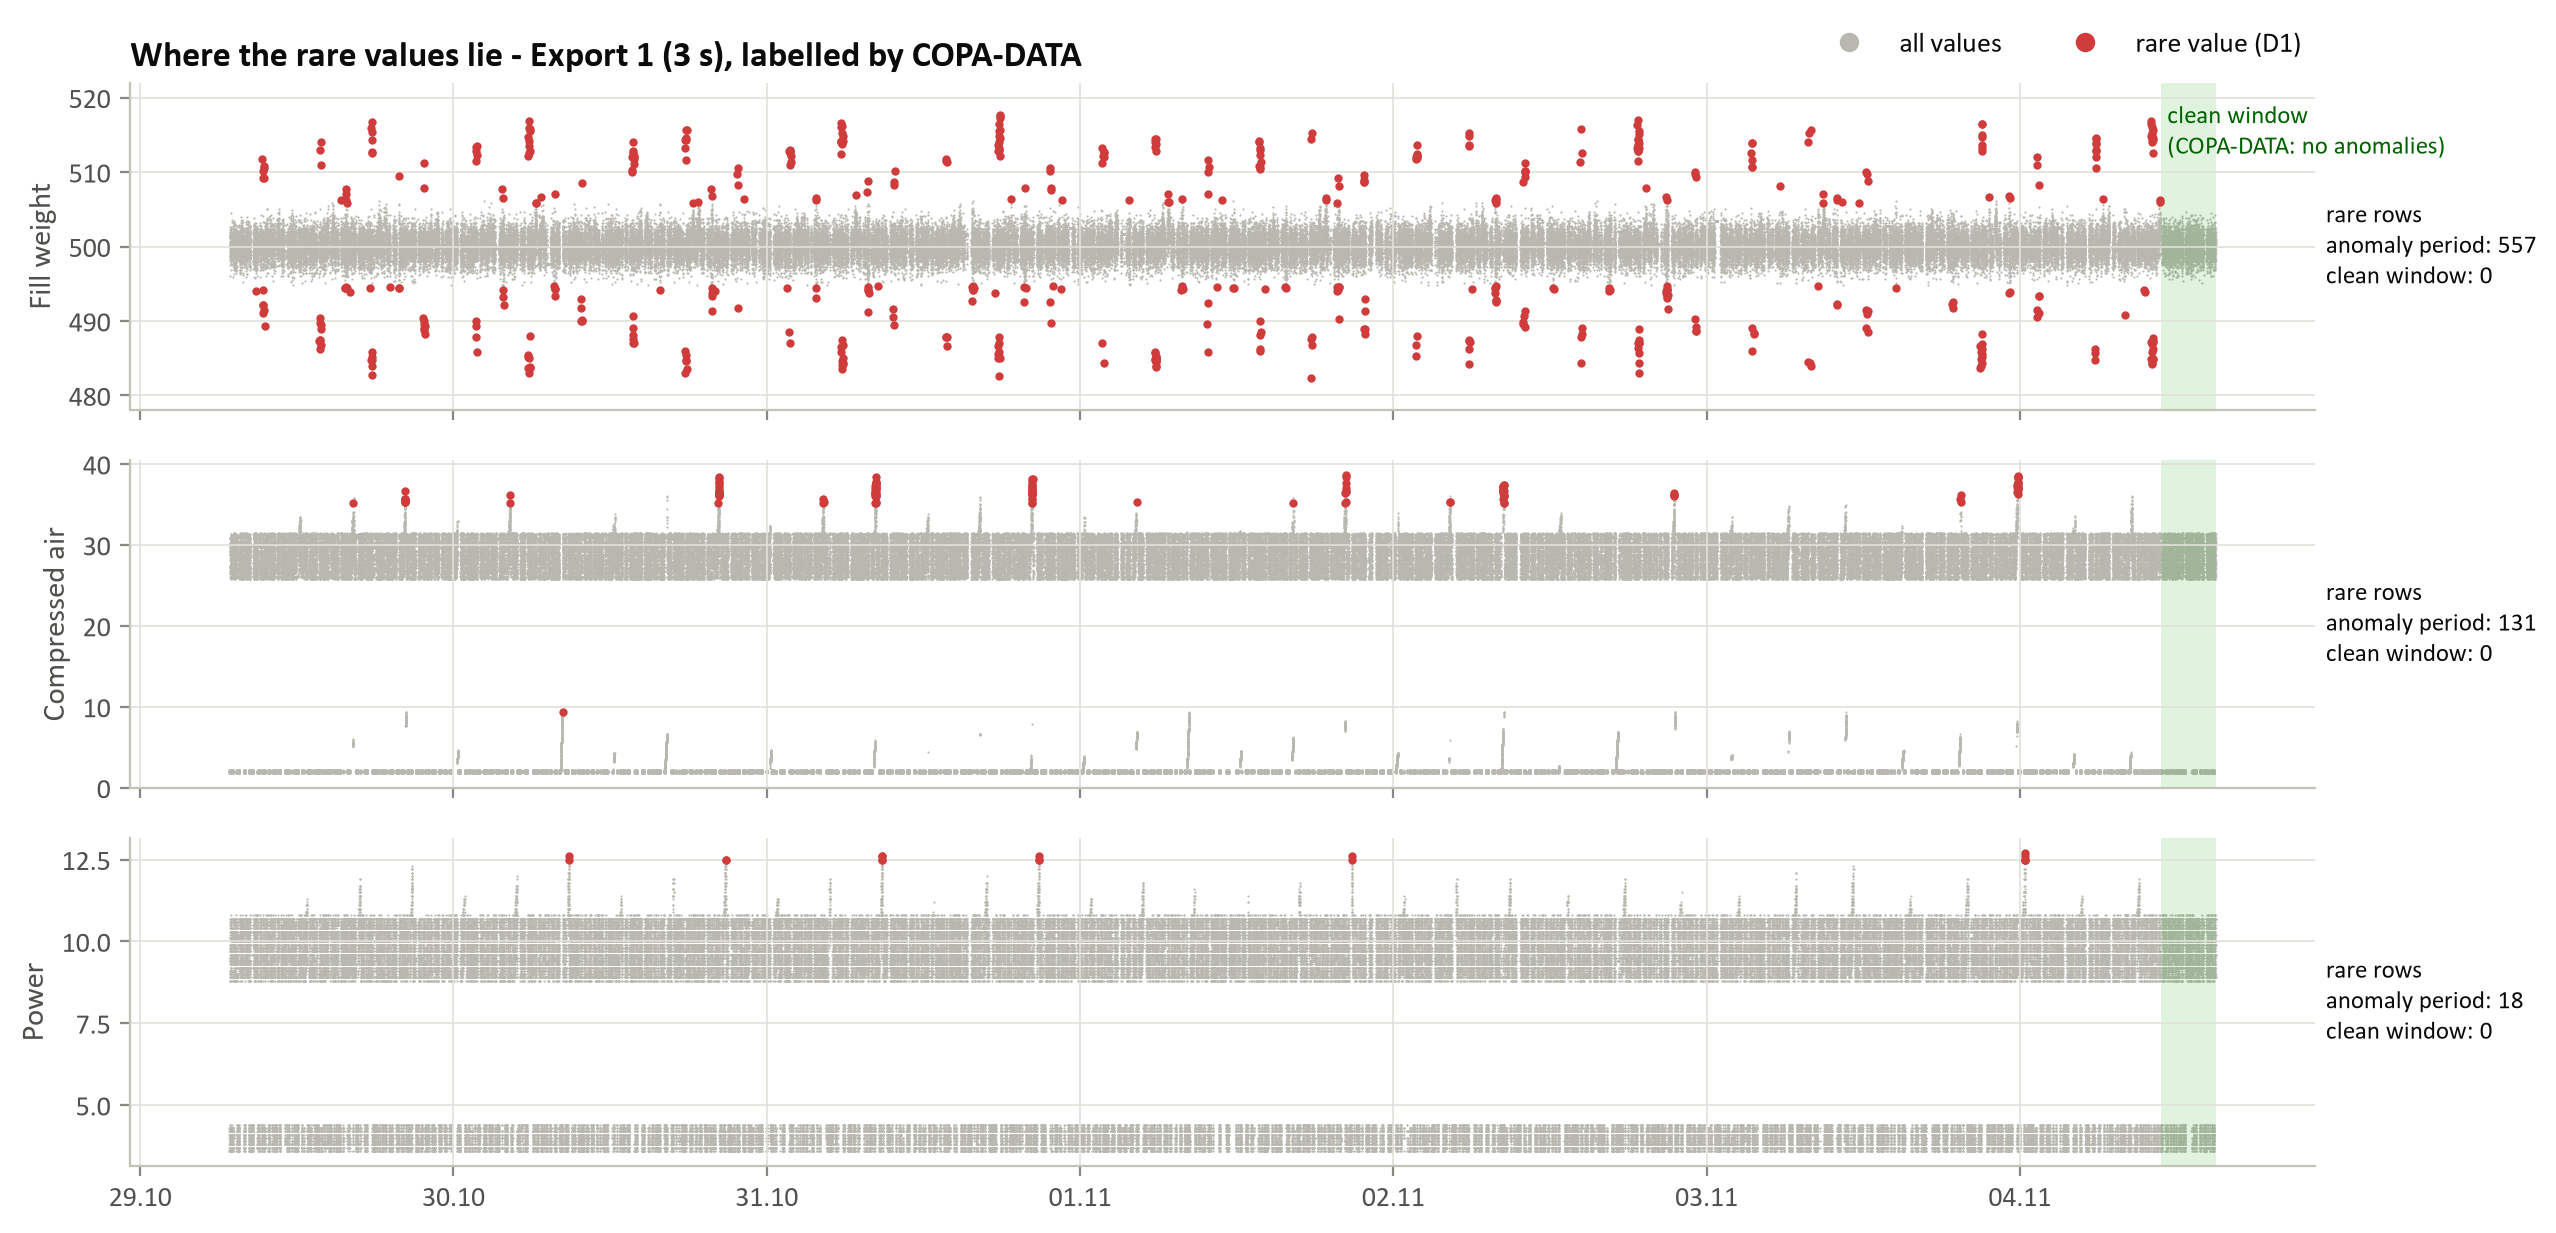

rare-value events: 165 in the anomaly period, 0 in the clean window


,rank,start,end,duration_s,rare_rows,signals,rarest_signal,rarest_value,rarest_share_pct,state,period
0,1,2026-10-29 09:22:03,2026-10-29 09:28:24,381.0,11,fill_weight,fill_weight,492.1,0.000811,running,anomaly
1,2,2026-10-29 13:43:18,2026-10-29 13:51:33,495.0,12,fill_weight,fill_weight,489.8,0.000811,running,anomaly
2,3,2026-10-29 17:41:48,2026-10-29 17:45:27,219.0,12,fill_weight,fill_weight,516.7,0.000811,running,anomaly
3,4,2026-10-29 19:49:00,2026-10-29 19:50:30,90.0,3,fill_weight,fill_weight,509.5,0.000811,running,anomaly
4,5,2026-10-29 21:41:36,2026-10-29 21:47:51,375.0,9,fill_weight,fill_weight,488.8,0.000811,running,anomaly
5,6,2026-10-30 03:48:33,2026-10-30 03:48:36,3.0,2,fill_weight,fill_weight,493.2,0.000811,running,anomaly
6,7,2026-10-30 05:41:57,2026-10-30 05:43:09,72.0,5,fill_weight,fill_weight,485.5,0.000811,running,anomaly
7,8,2026-10-30 05:45:57,2026-10-30 05:51:15,318.0,13,fill_weight,fill_weight,516.8,0.000811,running,anomaly
8,9,2026-10-30 09:48:06,2026-10-30 09:51:00,174.0,5,fill_weight,fill_weight,508.5,0.000811,running,anomaly
9,10,2026-10-30 13:41:51,2026-10-30 13:42:30,39.0,3,fill_weight,fill_weight,510.3,0.000811,running,anomaly


In [7]:
show("fig03_where_rare_values_lie_export1.png")
ev = pd.read_csv(TAB / "rare_value_events_old_3s.csv")
print(f"rare-value events: {(ev.period == 'anomaly').sum()} in the anomaly period, {(ev.period == 'clean').sum()} in the clean window")
display(ev.head(15))

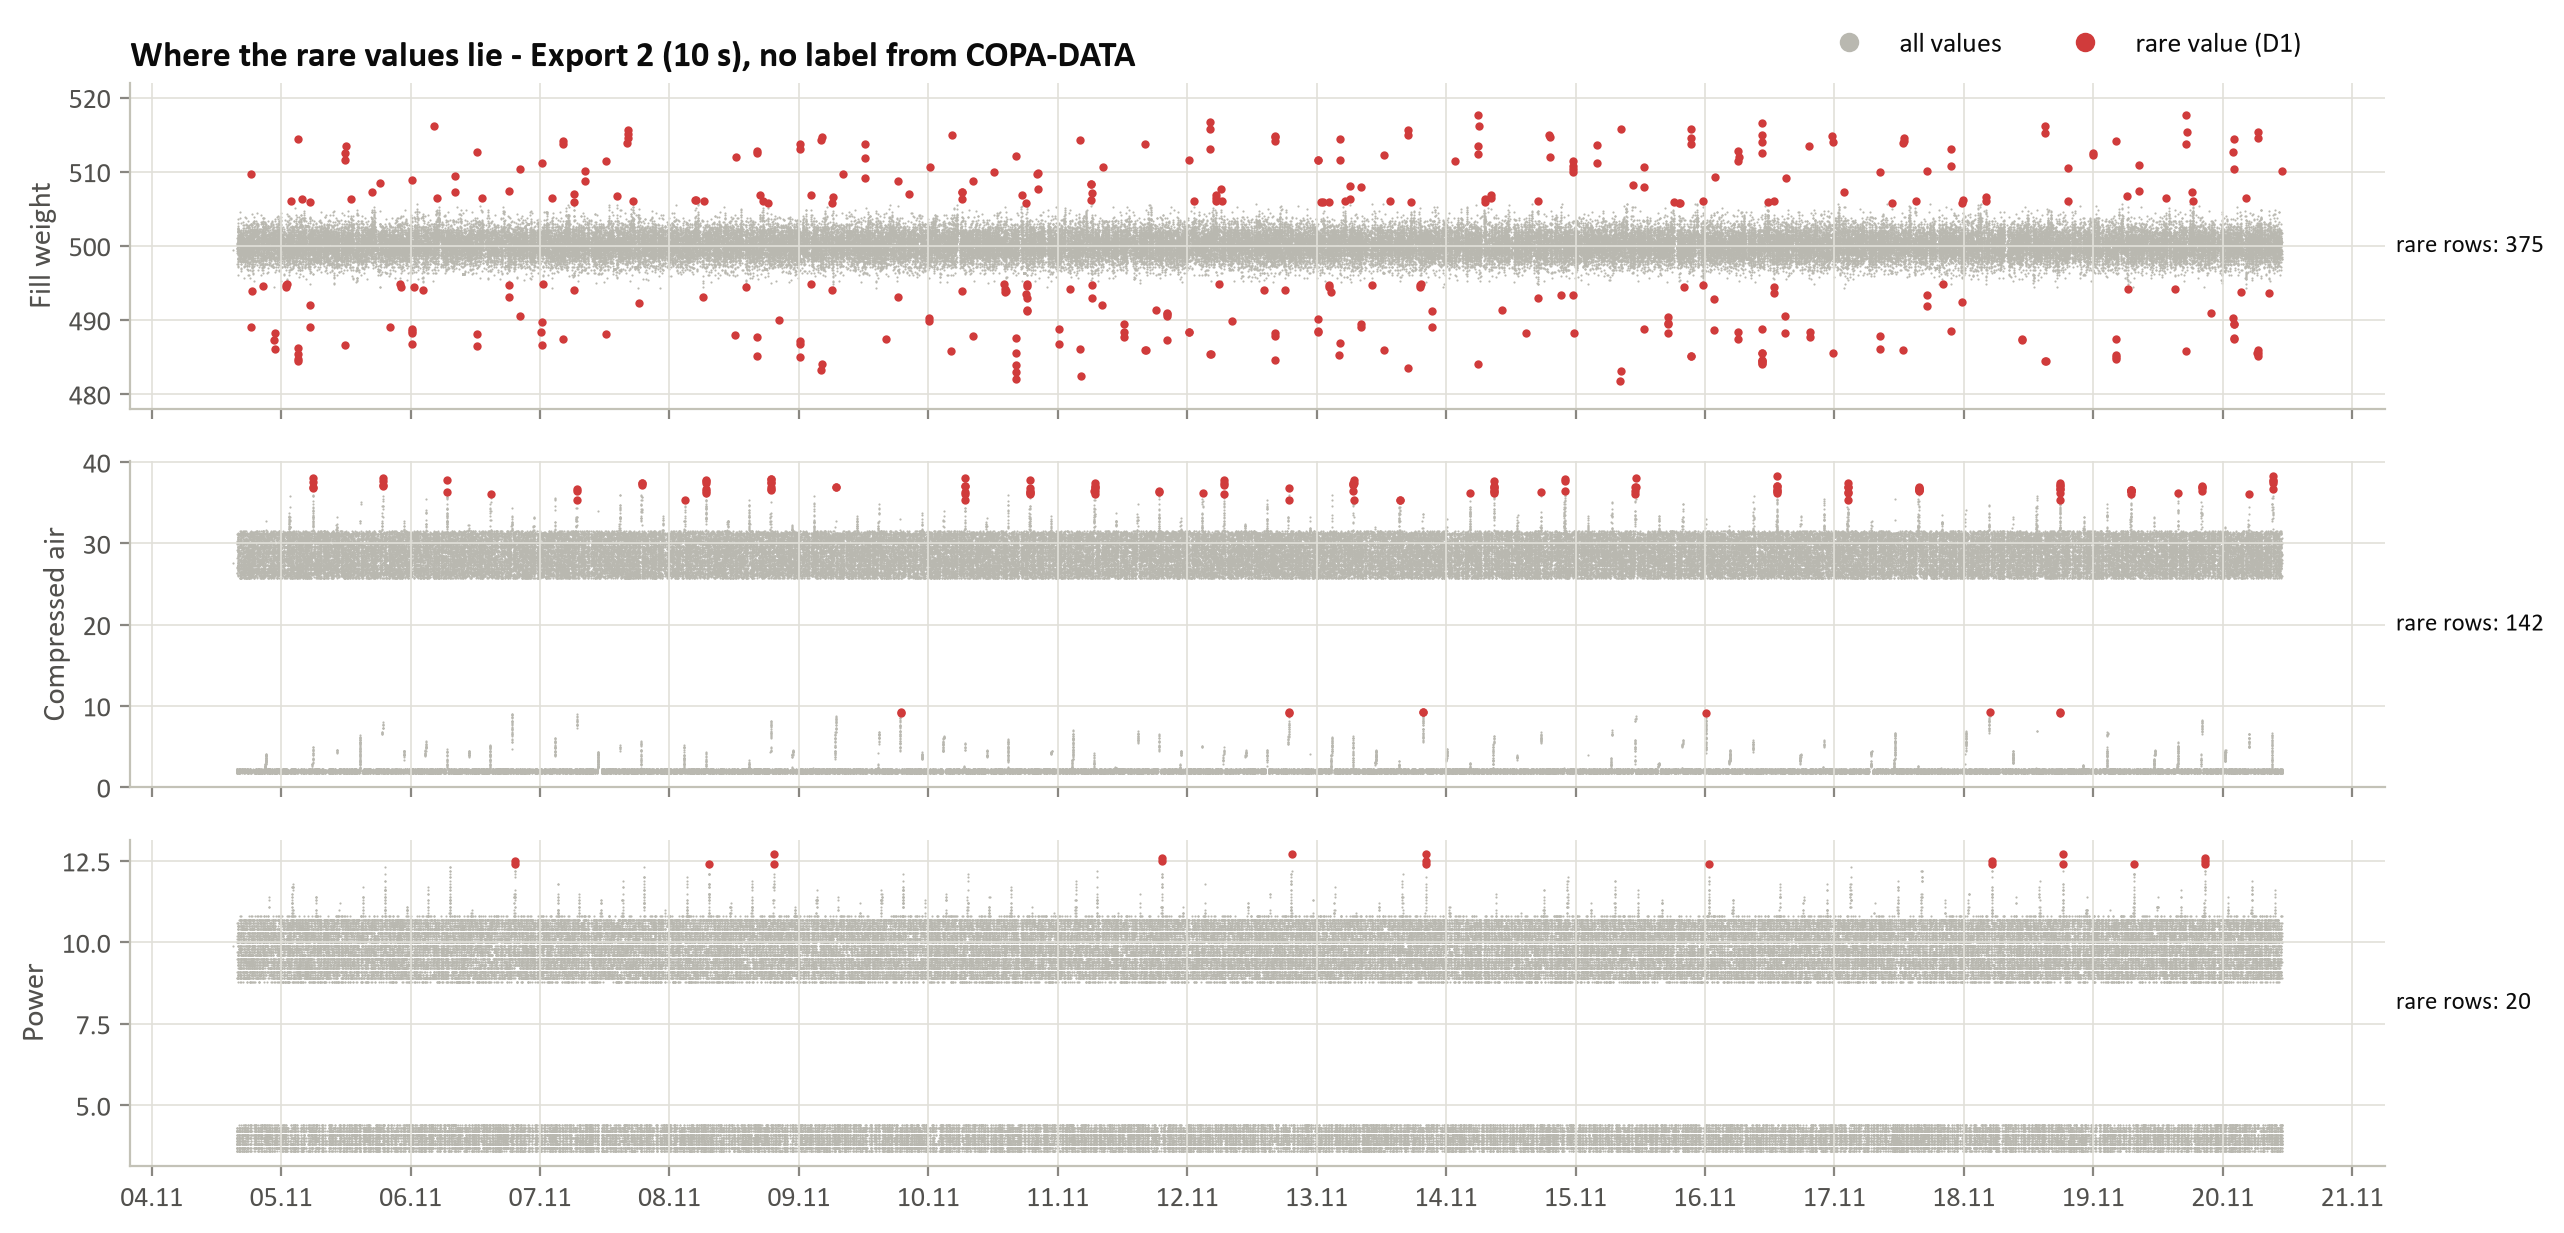

In [8]:
show("fig03b_where_rare_values_lie_export2.png")   # Export 2 has no label, but the same pattern

## 4 · What the anomalies look like
Comparing the anomaly period with the clean window gives three types that never occur in the clean window:
**A** compressed-air drift, **B** power drift, **C** fill-weight disturbance. Machine stops are normal (same rate in both).

max            min       
period              anomaly  clean anomaly  clean
state   signal                                   
running compair        38.6   31.5    25.8   25.8
        fill_weight   517.7  504.6   482.4  495.1
        power          12.7   10.8     8.8    8.8
stopped compair         9.4    2.2     1.8    1.8
        power           4.4    4.4     3.6    3.6

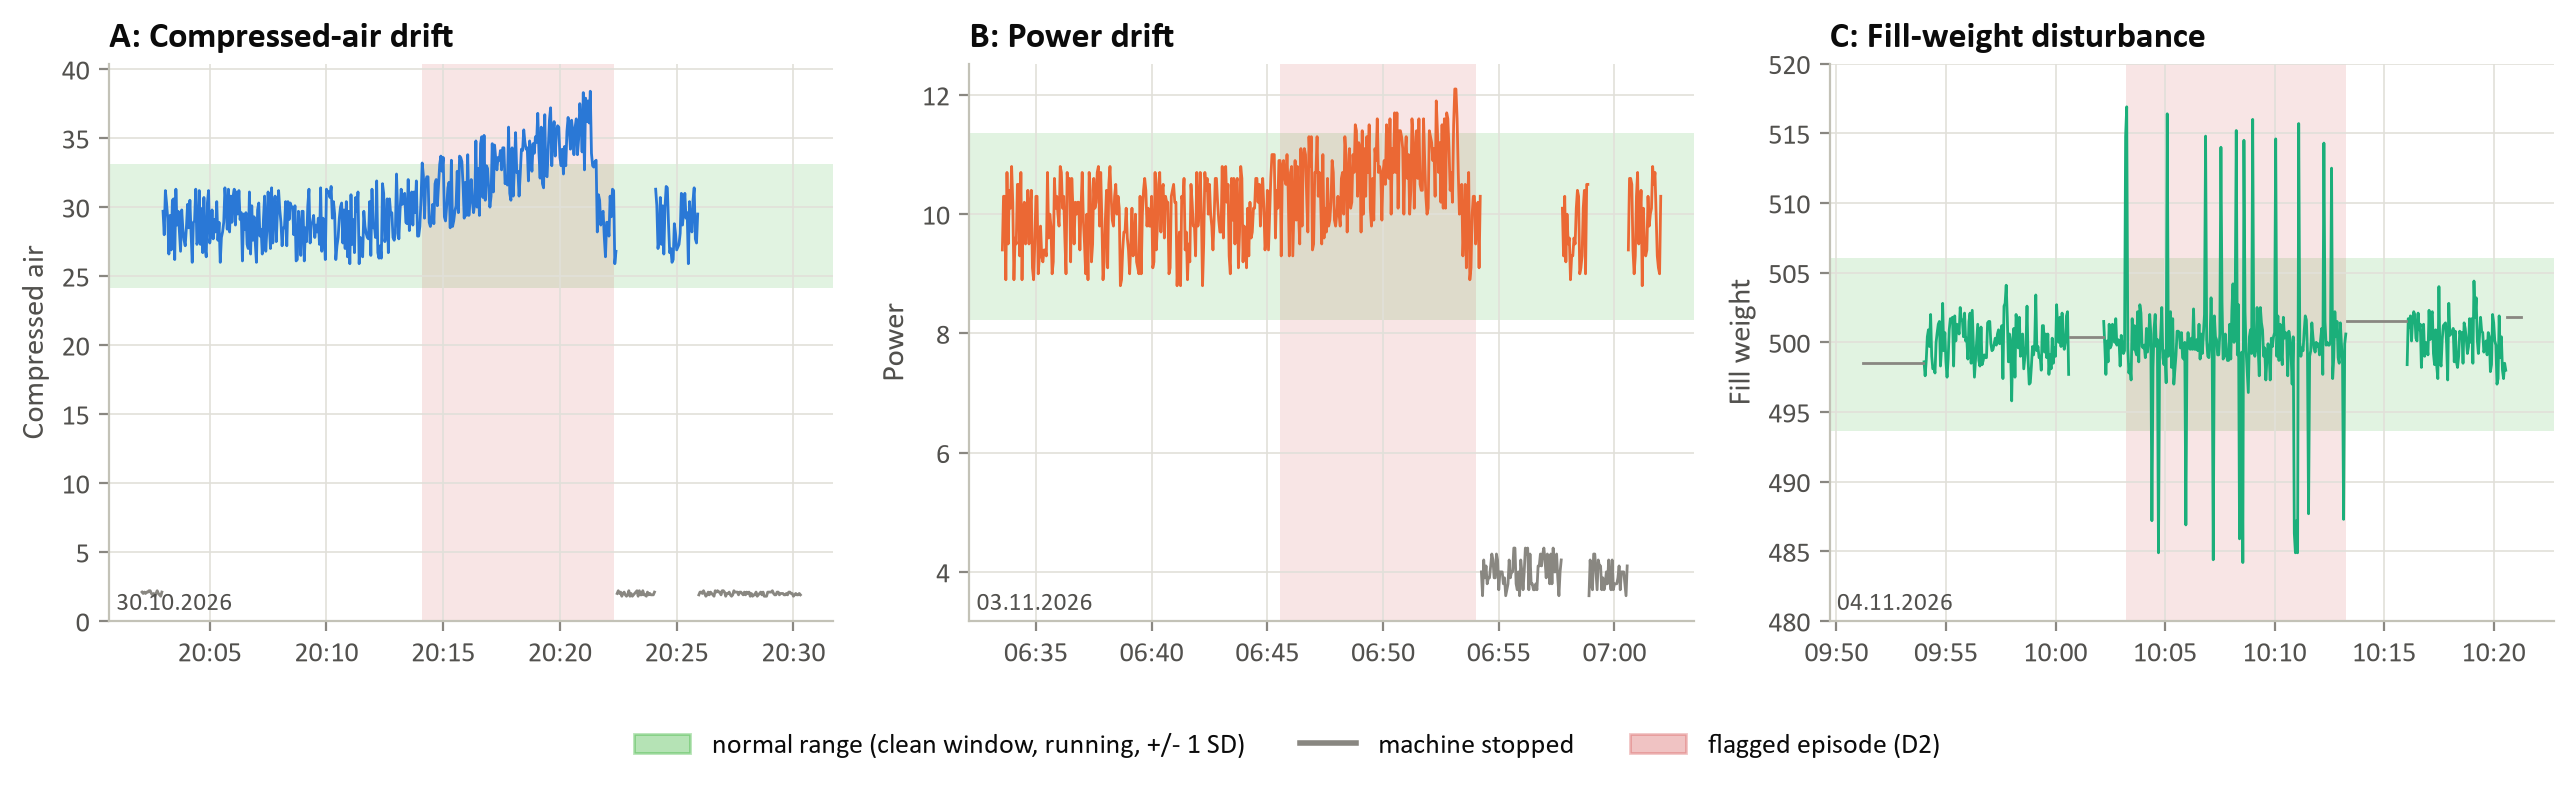

In [9]:
rng = pd.read_csv(TAB / "signal_ranges_by_period.csv")
display(rng.pivot_table(index=["state", "signal"], columns="period", values=["min", "max"]).round(1))
show("fig04_anomaly_types.png")

## 5 · When they happen
Each tick is one episode (D2 clean envelope). The onsets repeat at fixed times in a 4-hour cycle,
which random noise would not do. This is the strongest evidence that the episodes are the injected anomalies.

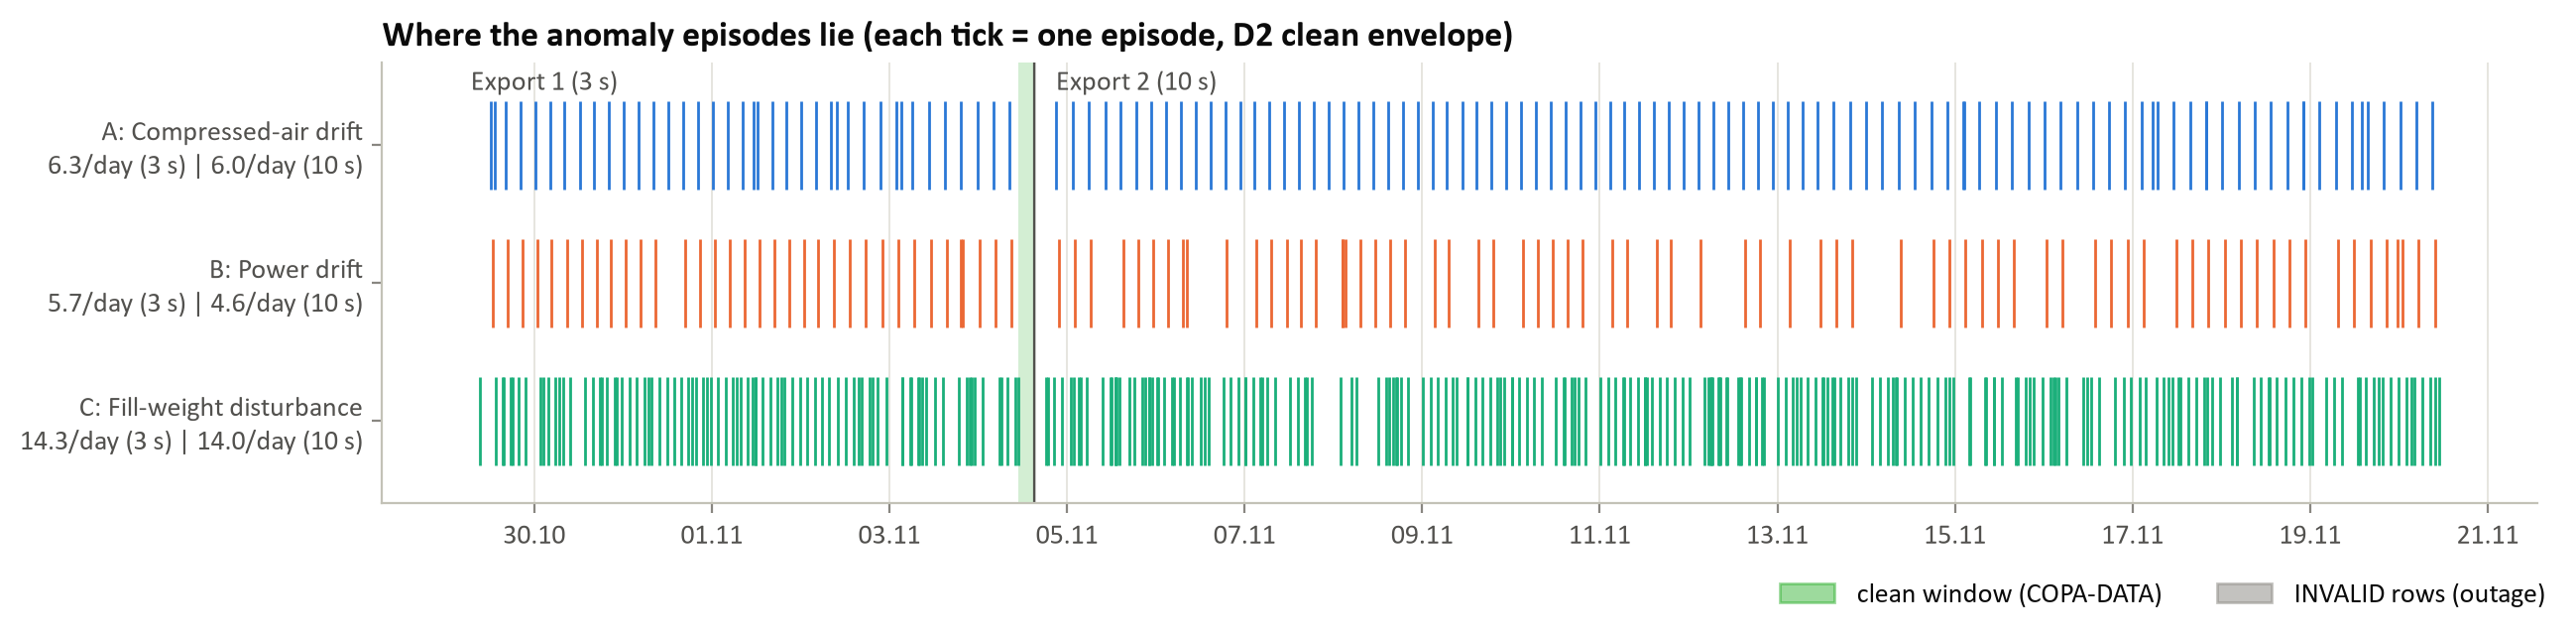

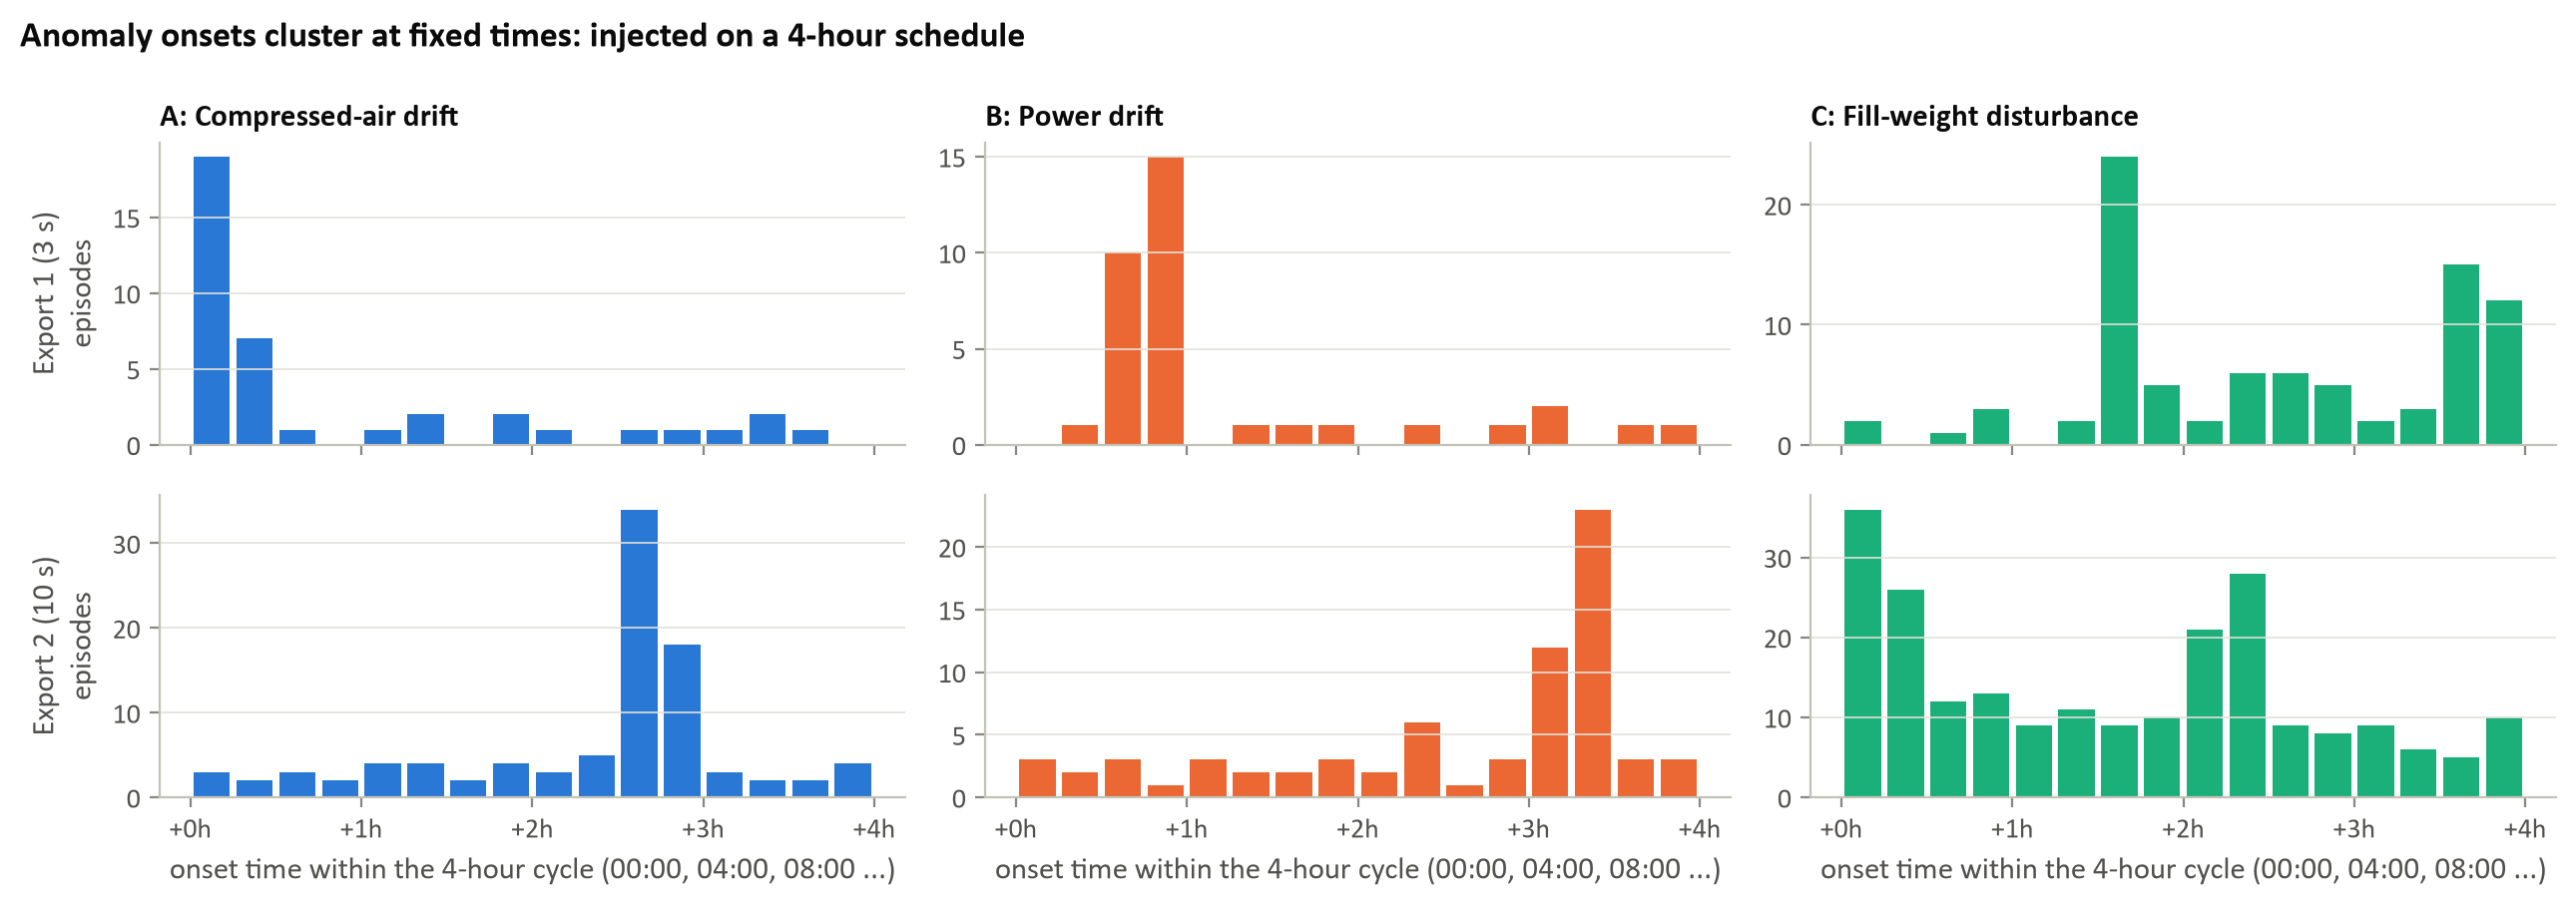

,export,type,type_name,episodes,best_30min_share_pct,best_window_start_min,best_window,uniform_expectation_pct
0,old_3s,A,Compressed-air drift,39,66.666667,0,0:00-0:30,12.5
1,old_3s,B,Power drift,35,71.428571,30,0:30-1:00,12.5
2,old_3s,C,Fill-weight disturbance,88,34.090909,94,1:34-2:04,12.5
3,new_10s,A,Compressed-air drift,95,54.736842,139,2:19-2:49,12.5
4,new_10s,B,Power drift,72,52.777778,183,3:03-3:33,12.5
5,new_10s,C,Fill-weight disturbance,222,29.729730,10,0:10-0:40,12.5


In [10]:
show("fig05_anomaly_calendar.png")
show("fig10_anomaly_schedule.png")
display(pd.read_csv(TAB / "anomaly_schedule_4h_cycle.csv"))

## 6 · Research questions (first answers)

### RQ1: detection methods (Export 1)

,label,flagged_pct,events_per_h_anomaly_period,false_alarms_per_day,episodes_detected_pct,alarm_events_on_reference_pct,median_warning_before_drift_peak_s
0,D1 Frequency ranking,0.39,1.11,0.0,59.26,83.03,40.5
1,D2 Clean envelope,7.21,1.31,0.0,100.00,100.00,342.0
2,D3 Isolation Forest,0.94,0.65,0.0,49.38,100.00,175.5


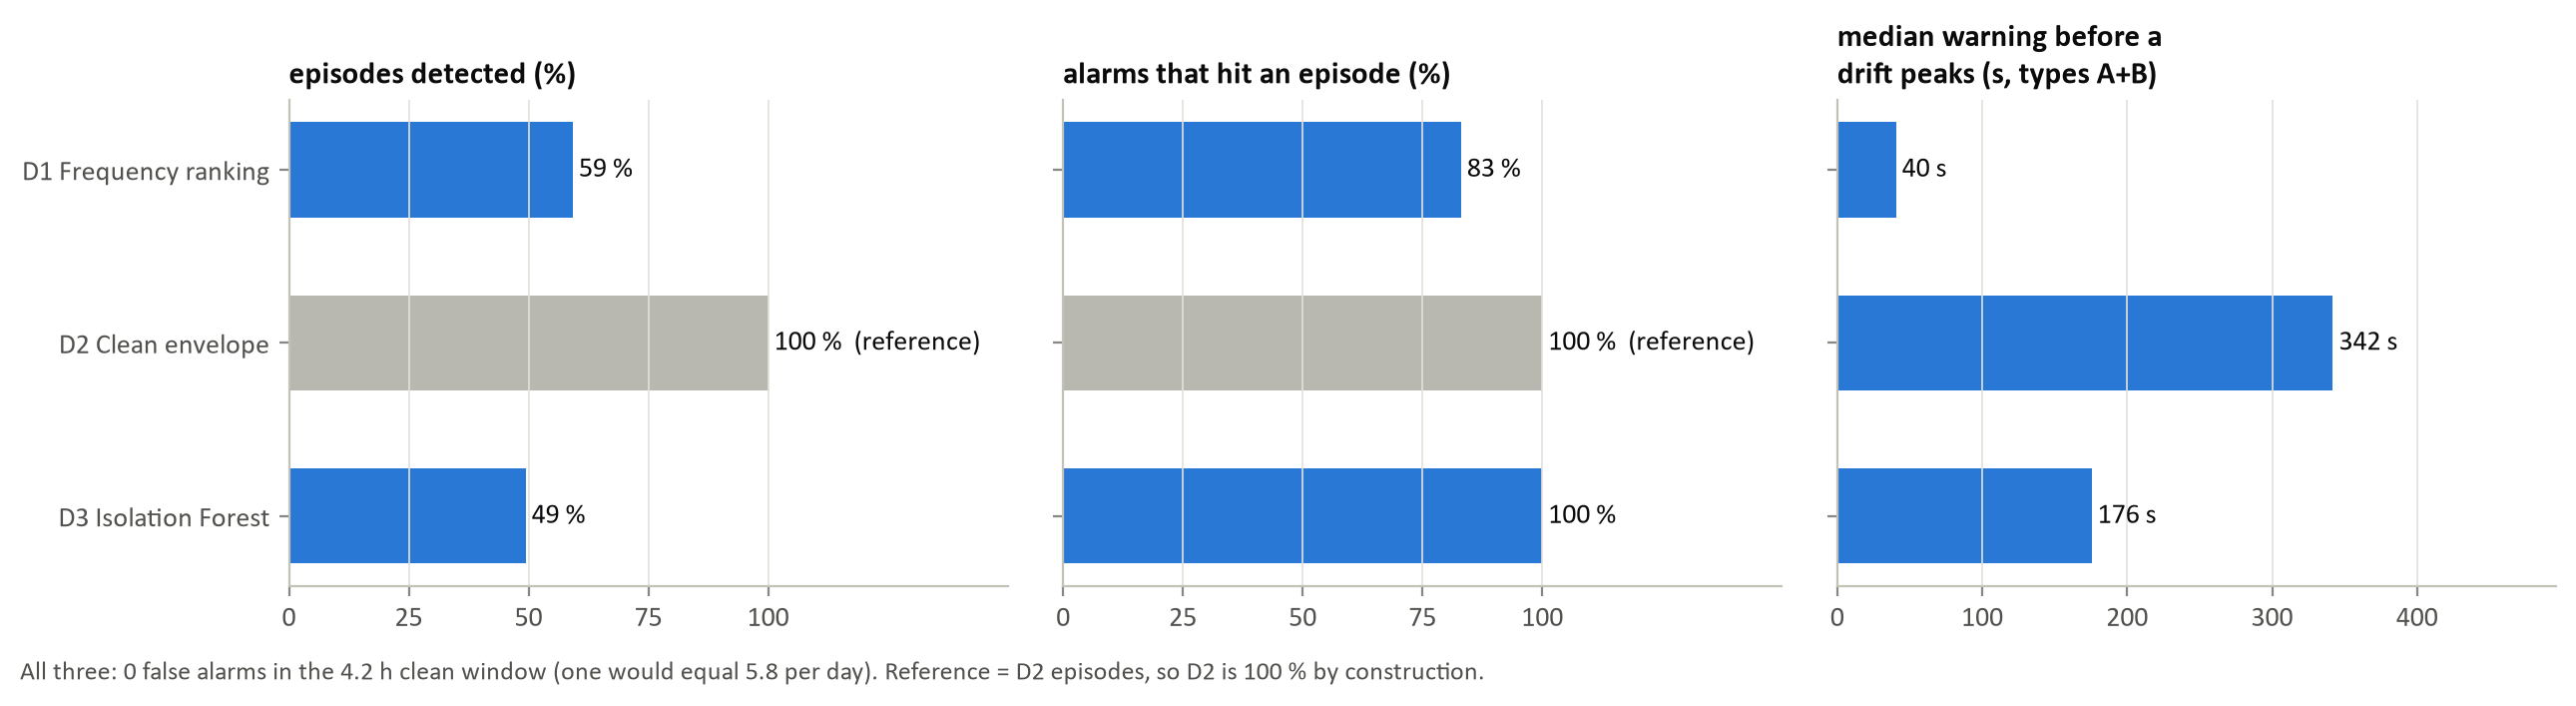

In [11]:
display(Markdown("### RQ1: detection methods (Export 1)"))
display(pd.read_csv(TAB / "rq1_detector_comparison.csv")[["label", "flagged_pct", "events_per_h_anomaly_period", "false_alarms_per_day",
        "episodes_detected_pct", "alarm_events_on_reference_pct", "median_warning_before_drift_peak_s"]].round(2))
show("fig06_rq1_detectors.png")

### RQ2: online (causal) vs. batch (centred)

,type,type_name,batch_episodes,online_detected_pct,median_extra_delay_online_s,p90_extra_delay_online_s,share_detected_later_pct
0,A,Compressed-air drift,36,100.0,0.0,9.0,27.8
1,B,Power drift,38,92.1,30.0,30.0,94.3
2,C,Fill-weight disturbance,91,95.6,30.0,30.0,74.7


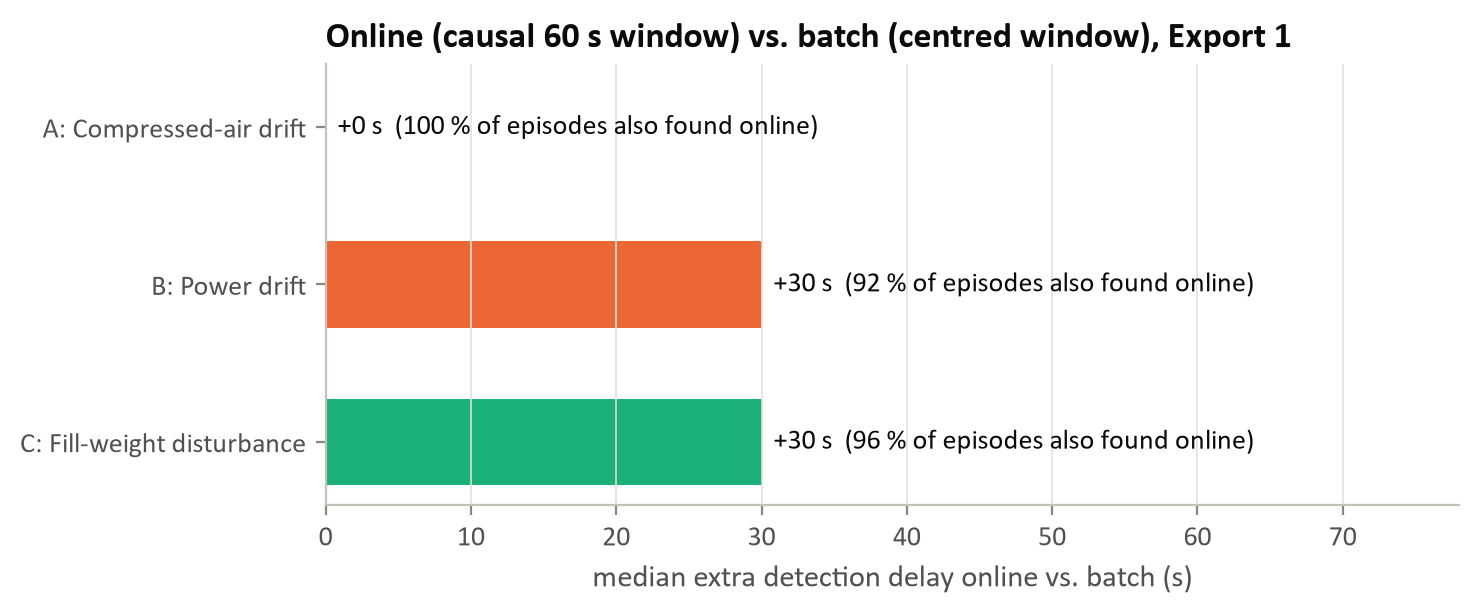

In [12]:
display(Markdown("### RQ2: online (causal) vs. batch (centred)"))
display(pd.read_csv(TAB / "rq2_online_vs_batch.csv").round(1))
show("fig07_rq2_online_vs_batch.png", width=800)

### RQ3: archive parameters

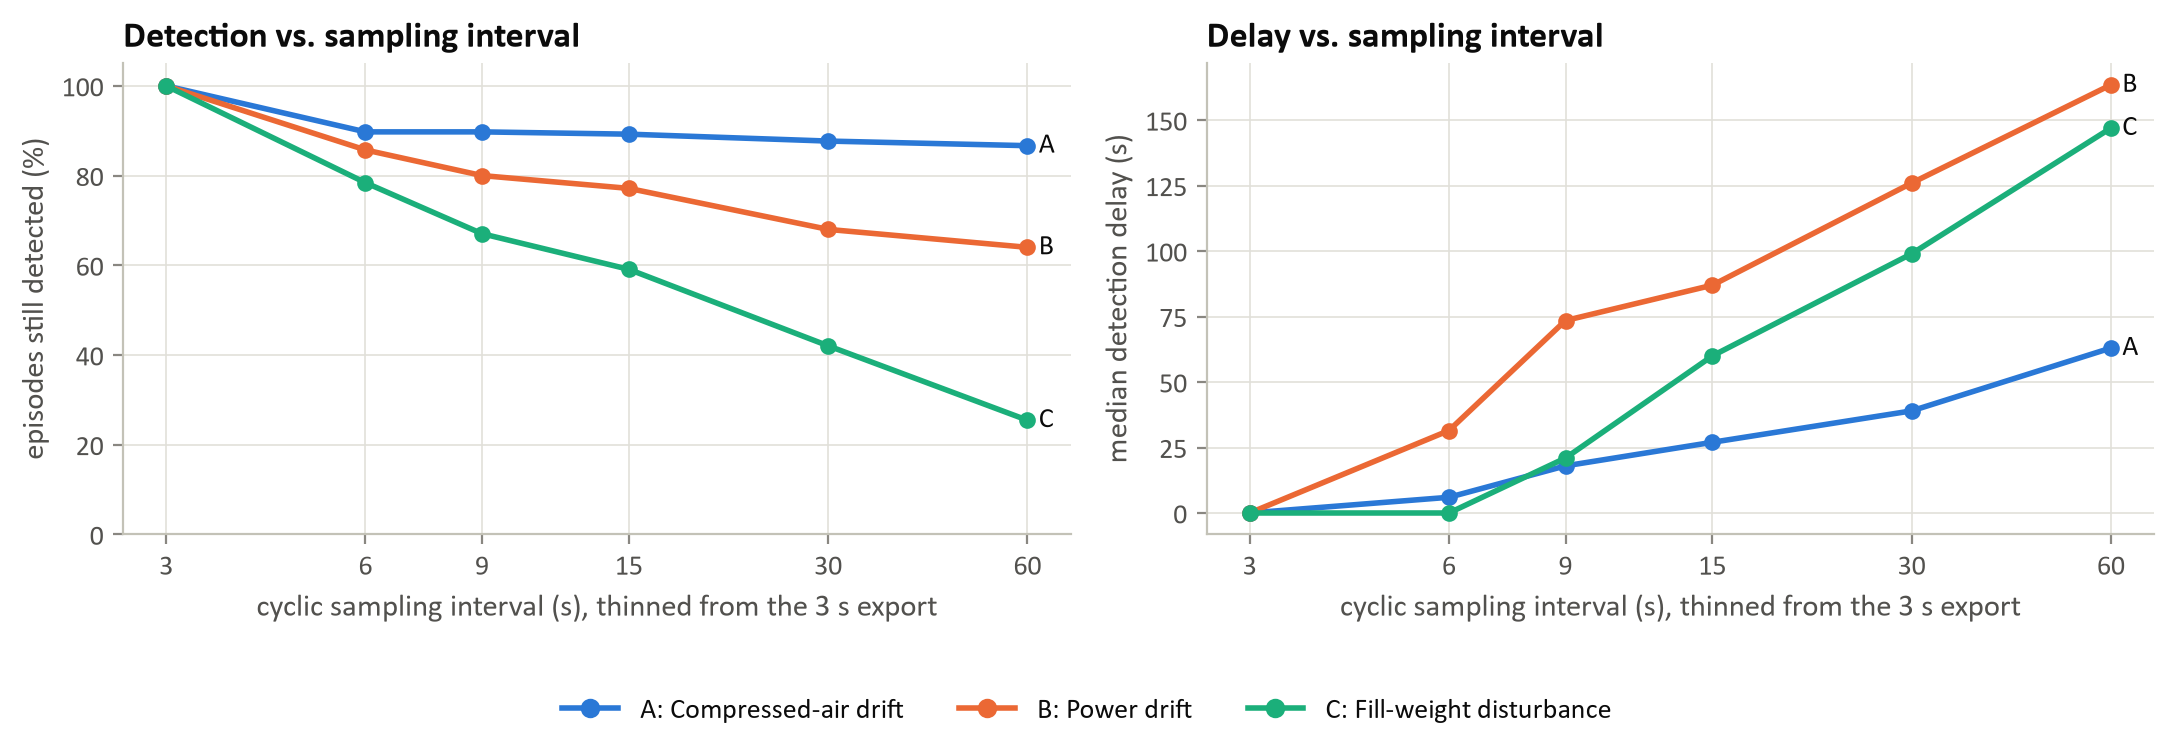

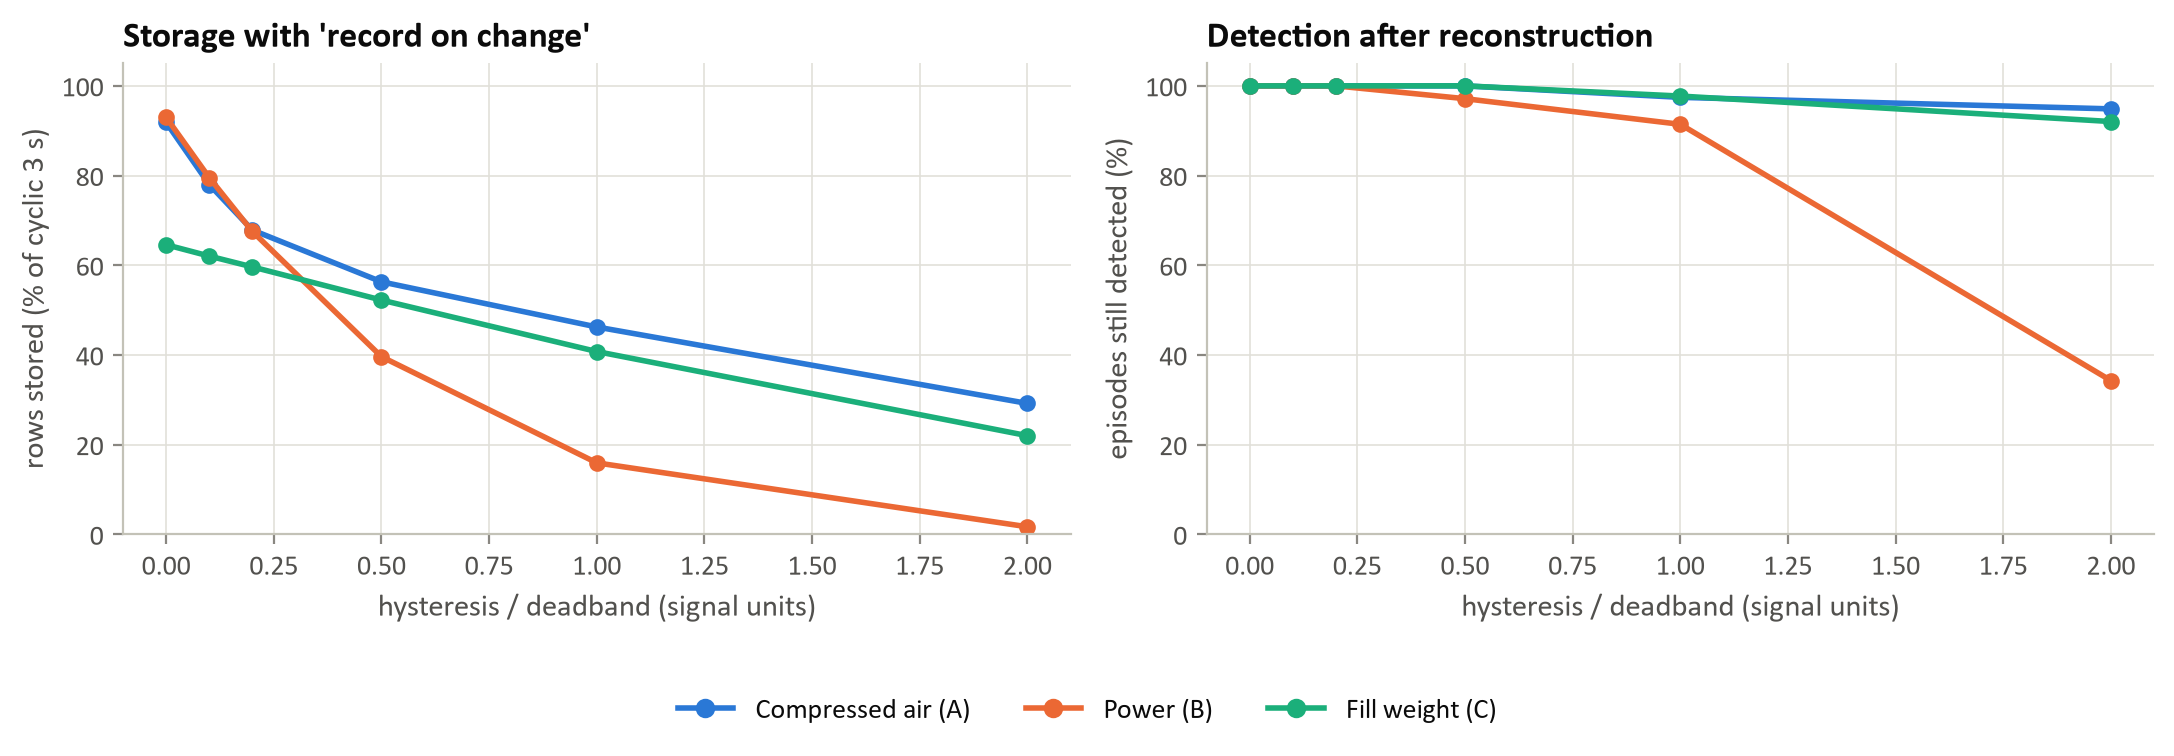

,interval_s,type,type_name,offsets,detected_pct,median_delay_s,rows_per_day_per_variable
0,3,A,Compressed-air drift,1,100.0,0.0,28800.0
1,3,B,Power drift,1,100.0,0.0,28800.0
2,3,C,Fill-weight disturbance,1,100.0,0.0,28800.0
3,6,A,Compressed-air drift,2,89.7,6.0,14400.0
4,6,B,Power drift,2,85.7,31.5,14400.0
5,6,C,Fill-weight disturbance,2,78.4,0.0,14400.0
6,9,A,Compressed-air drift,3,89.7,18.0,9600.0
7,9,B,Power drift,3,80.0,73.5,9600.0
8,9,C,Fill-weight disturbance,3,67.0,21.0,9600.0
9,15,A,Compressed-air drift,5,89.2,27.0,5760.0


In [13]:
display(Markdown("### RQ3: archive parameters"))
show("fig08_rq3_sampling_interval.png")
show("fig09_rq3_deadband.png")
display(pd.read_csv(TAB / "rq3_sampling_interval.csv").round(1))

## 7 · Explore single episodes (interactive)
Pick an export and a rank from the anomaly list (sorted by severity), then press ▶ again.
In the browser version of Colab the two parameters appear as a form; in VS Code just edit the values.

In [ ]:
# @title Episode explorer
EXPORT = "old_3s"   # @param ["old_3s", "new_10s"]
RANK = 1            # @param {type:"slider", min:1, max:300, step:1}

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import copa_data as CD

WIDE = globals().setdefault("WIDE", {})
if EXPORT not in WIDE:
    WIDE[EXPORT] = CD.load_export(EXPORT)[0]     # about 5 s the first time
w = WIDE[EXPORT]
lst = pd.read_csv(TAB / f"anomaly_list_by_severity_{EXPORT}.csv", parse_dates=["start", "end", "peak_time"])
e = lst.iloc[min(RANK, len(lst)) - 1]
s = w.loc[e.start - pd.Timedelta(minutes=15): e.end + pd.Timedelta(minutes=10)]
cols = ["fill_weight", "compair", "power", "speed"]
fig = make_subplots(rows=4, cols=1, shared_xaxes=True, vertical_spacing=0.04, subplot_titles=cols)
for i, c in enumerate(cols, start=1):
    fig.add_trace(go.Scatter(x=s.index, y=s[c], mode="lines", line=dict(width=1, color="#2a78d6"), name=c), row=i, col=1)
    fig.add_vrect(x0=e.start, x1=e.end, fillcolor="#d03b3b", opacity=0.15, line_width=0, row=i, col=1)
fig.update_layout(height=760, showlegend=False, template="simple_white",
                  title=f"#{RANK} {e.type_name}: {e.start:%d.%m.%Y %H:%M:%S}, {e.duration_s:.0f} s, severity {e.severity_sigma:.1f} SD ({e.period})")
fig.show()
display(lst.head(15)[["rank", "type_name", "start", "duration_s", "peak_feature", "peak_value", "severity_sigma", "period"]])